# Towards Transparent Quantum Execution: A New Framework in Qiskit

Let's start by picking a backend to use throughout the notebook.

In [1]:
from qiskit_ibm_runtime import QiskitRuntimeService, Sampler, Estimator, Executor, QuantumProgram
from qiskit_ibm_runtime.fake_provider import FakeManilaV2

try:
    service = QiskitRuntimeService()
    ibm_backend = service.backend("ibm_pittsburgh")
except:
    ibm_backend = None

if USE_REAL_BACKEND := False:
    backend = ibm_backend
else:
    backend = FakeManilaV2()

print(f"Backend: {backend.name}, {backend.num_qubits} qubits")

qiskit_runtime_service.__init__:WARNING:2026-11-17 14:18:27,907: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (premium, internal), the available account instances are: engine-premium-eu, engine-internal-eu, engine-internal-us, engine-premium-us. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-11-17 14:18:27,908: Using instance: engine-premium-us, plan: premium


Backend: fake_manila, 5 qubits


## Primitives

The two main entry points for running circuits on IBM hardware are `Sampler` and `Estimator`.

### Sampler: Hello World

We'll prepare a 3-qubit GHZ state and sample it to see how the results come back.

In [2]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# GHZ circuit: |000⟩ + |111⟩
qc = QuantumCircuit(3)
qc.h(0)
qc.cx(0, 1)
qc.cx(1, 2)
qc.measure_all()

pm = generate_preset_pass_manager(optimization_level=1, backend=backend)
isa_qc = pm.run(qc)

sampler = Sampler(mode=backend)
job = sampler.run([isa_qc], shots=4096)
result = job.result()

# One BitArray per classical register
data = result[0].data
print(f"Classical registers: {list(data.keys())}")
print(f"BitArray: shape={data.meas.shape}, num_shots={data.meas.num_shots}, num_bits={data.meas.num_bits}")
print()

# Convenience: counts dict
counts = data.meas.get_counts()
print("Counts:", counts)
print()

# Direct computation on bit data: GHZ fidelity
ghz_frac = (counts.get("000", 0) + counts.get("111", 0)) / sum(counts.values())
print(f"GHZ fidelity (lower bound): {ghz_frac:.3f}")

Classical registers: ['meas']
BitArray: shape=(), num_shots=4096, num_bits=3

Counts: {'011': 201, '111': 1702, '000': 1745, '110': 94, '010': 48, '100': 165, '001': 79, '101': 62}

GHZ fidelity (lower bound): 0.842


### Estimator: Hello World

The estimator does the same kind of thing, but returns expectation values instead of shot data.

In [4]:
from qiskit.quantum_info import SparsePauliOp

# Same GHZ state, without measurements
qc_est = QuantumCircuit(3)
qc_est.h(0)
qc_est.cx(0, 1)
qc_est.cx(1, 2)
isa_est = pm.run(qc_est)

# Observables must be mapped to physical qubits via the transpiler layout
observable = SparsePauliOp("ZZI").apply_layout(isa_est.layout)

estimator = Estimator(mode=backend)
job = estimator.run([(isa_est, observable)])
result = job.result()

evs = result[0].data.evs
stds = result[0].data.stds
print(f"⟨ZZI⟩ = {evs:.4f} ± {stds:.4f}")

⟨ZZI⟩ = 0.9779 ± 0.0107


### Broadcasting

If we want to sweep a parameter over many values or measure several observables at once, we can use broadcasting to avoid submitting separate jobs.

evs shape:  (20, 2)  — broadcast of params (20, 1) × observables (2,)
stds shape: (20, 2)


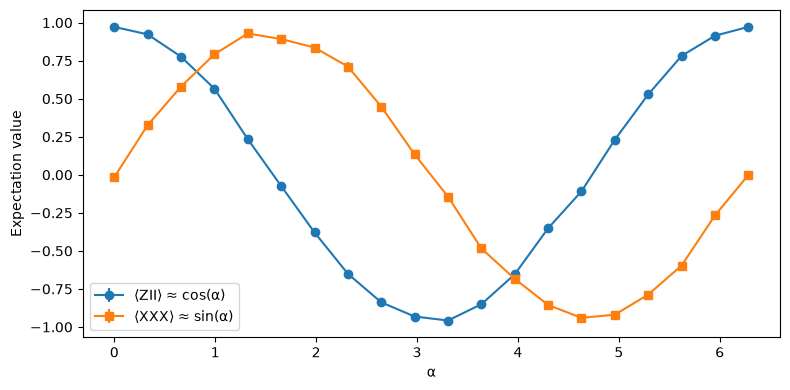

In [5]:
import matplotlib.pyplot as plt
from qiskit.circuit import Parameter

# Parametrized circuit with one angle
alpha = Parameter("α")
qc_param = QuantumCircuit(3)
qc_param.ry(alpha, 0)
qc_param.cx(0, 1)
qc_param.cx(1, 2)

isa_param = pm.run(qc_param)

# State is cos(α/2)|000⟩ + sin(α/2)|111⟩
# ⟨ZII⟩ = cos(α),  ⟨XXX⟩ = sin(α)
obs_z = SparsePauliOp("ZII").apply_layout(isa_param.layout)
obs_x = SparsePauliOp("XXX").apply_layout(isa_param.layout)

# Sweep α over 20 values → parameter_values shape (20, 1, 1) → extrinsic (20, 1)
alpha_vals = np.linspace(0, 2 * np.pi, 20)
params = alpha_vals.reshape(20, 1, 1)

# Broadcasting: params (20, 1) × observables (2,) → evs shape (20, 2)
estimator = Estimator(mode=backend)
job = estimator.run([(isa_param, [obs_z, obs_x], params)])
result = job.result()

evs = result[0].data.evs
stds = result[0].data.stds
print(f"evs shape:  {evs.shape}  — broadcast of params (20, 1) × observables (2,)")
print(f"stds shape: {stds.shape}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(alpha_vals, evs[:, 0], yerr=stds[:, 0], fmt="o-", label="⟨ZII⟩ ≈ cos(α)")
ax.errorbar(alpha_vals, evs[:, 1], yerr=stds[:, 1], fmt="s-", label="⟨XXX⟩ ≈ sin(α)")
ax.set_xlabel("α")
ax.set_ylabel("Expectation value")
ax.legend()
plt.tight_layout()

### Options

Primitives accept options to control things like error suppression — here we'll look at what's available and try out Pauli twirling on a real backend.

In [6]:
from rich.pretty import pprint

if ibm_backend is not None:
    sampler = Sampler(mode=ibm_backend)
    pprint(sampler.options)

ModuleNotFoundError: No module named 'rich'

Now let's actually run the parameter sweep from above on a real backend with twirling enabled.

<RuntimeJobV2('dbuah8s9po4c73cepuh0', 'executor')>
BitArray: shape=(20,), num_shots=4096, num_bits=3


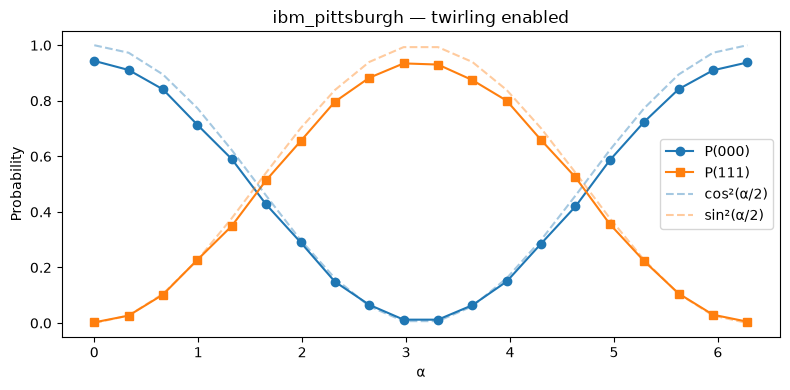

In [9]:
if ibm_backend is not None:
    # Parametric circuit with measurements for sampler
    qc_param_meas = qc_param.copy()
    qc_param_meas.measure_all()

    pm_ibm = generate_preset_pass_manager(optimization_level=1, backend=ibm_backend)
    isa_param_ibm = pm_ibm.run(qc_param_meas)

    sampler_ibm = Sampler(mode=ibm_backend)
    sampler_ibm.options.twirling.enable_gates = True
    sampler_ibm.options.twirling.enable_measure = True
    sampler_ibm.options.execution.scheduler_timing = True

    # Sweep α over 20 values
    params = alpha_vals.reshape(20, 1)
    # job = sampler_ibm.run([(isa_param_ibm, params)], shots=4096)
    job = service.job("dbuah8s9po4c73cepuh0")
    print(job)
    result = job.result()

    data = result[0].data.meas
    print(f"BitArray: shape={data.shape}, num_shots={data.num_shots}, num_bits={data.num_bits}")

    # Extract P(000) and P(111) separately per angle
    p000, p111 = [], []
    for i in range(len(alpha_vals)):
        counts = data[i].get_counts()
        total = sum(counts.values())
        p000.append(counts.get("000", 0) / total)
        p111.append(counts.get("111", 0) / total)

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(alpha_vals, p000, "o-", label="P(000)")
    ax.plot(alpha_vals, p111, "s-", label="P(111)")
    ax.plot(alpha_vals, np.cos(alpha_vals / 2) ** 2, "--", color="C0", alpha=0.4, label="cos²(α/2)")
    ax.plot(alpha_vals, np.sin(alpha_vals / 2) ** 2, "--", color="C1", alpha=0.4, label="sin²(α/2)")
    ax.set_xlabel("α")
    ax.set_ylabel("Probability")
    ax.set_title(f"{ibm_backend.name} — twirling enabled")
    ax.legend()
    plt.tight_layout()

We can also visualize how the job's execution was chunked on hardware.

In [14]:
from qiskit_ibm_runtime.visualization import draw_chunk_timings
from samplomatic.quantum_program import ChunkTiming
ChunkTiming(result.metadata["executor"].chunk_timing).draw()

### Exercises

1. **Bell instead of GHZ** — Modify the Sampler hello-world to prepare a 2-qubit Bell state instead of a 3-qubit GHZ. Compute the correlation `P(00) + P(11)` from the counts.

2. **Multiple observables** — In the Estimator hello-world, estimate `⟨ZZI⟩`, `⟨ZIZ⟩`, and `⟨IZZ⟩` in a single job (pass a list of observables). Verify they're all close to 1 for a GHZ state.

3. **Broadcasting shape puzzle** — The parameter sweep broadcasts `(20, 1)` params against `(2,)` observables to get `(20, 2)` results. Add a second parameter sweep dimension (e.g. two different circuits) and predict the output shape before running it.

## Executor

`Executor` is the lower-level API that primitives are built on — it works with `QuantumProgram` objects and returns raw data.

### Hello World

At its simplest, we can wrap an ISA circuit in a `QuantumProgram` and get back raw boolean measurement arrays.

In [8]:
# Executor + CircuitItem: equivalent to a bare sampler job
program = QuantumProgram(shots=4096)
program.append_circuit_item(isa_qc)

executor = Executor(mode=backend)
job = executor.run(program)
result = job.result()

# Raw bool array: (shots, num_bits)
item = result[0]
meas = item["meas"]
print(f"meas shape: {meas.shape}  — (num_shots, num_bits)")
print(f"meas dtype: {meas.dtype}")

meas shape: (4096, 3)  — (num_shots, num_bits)
meas dtype: bool


### Samplomatic

`samplomatic` is a library for building randomized (e.g. twirled) circuits — it produces a template circuit plus a specification of how to randomize it.

In [ ]:
from samplomatic import build
from samplomatic.transpiler import generate_boxing_pass_manager

# Box the ISA circuit for Pauli twirling
boxing_pm = generate_boxing_pass_manager(
    enable_gates=True,
    enable_measures=True,
    twirling_strategy="active_circuit",
    twirling_group="pauli",
)
boxed = boxing_pm.run(isa_qc)

# Build the template circuit and samplex (randomization specification)
template, samplex = build(boxed)
print(f"Template parameters: {template.num_parameters}")

Here's what the template circuit looks like — notice the parameters that get filled in by each randomization.

In [ ]:
template.draw("mpl")

And this is the samplex, which describes the distribution each parameter is drawn from.

In [ ]:
samplex.draw()

Now we build a `QuantumProgram` with 32 randomizations and run it through the executor.

In [ ]:
# Build a twirled QuantumProgram
num_randomizations = 32
shots_per_rand = 128

program = QuantumProgram(shots=shots_per_rand)
program.append_samplex_item(template, samplex, shape=(num_randomizations,))

executor = Executor(mode=backend)
job = executor.run(program)
result = job.result()

# Raw result: bool arrays
item = result[0]
print(f"Result keys: {list(item.keys())}")
print(f"meas shape: {item['meas'].shape}  — (num_rand, shots_per_rand, num_bits)")
print(f"measurement_flips shape: {item['measurement_flips.meas'].shape}")

To recover the actual measurement outcomes, we undo the measurement twirling by XOR-ing out the flips.

In [ ]:
# Post-process: undo measurement twirling via XOR
meas = item["meas"] ^ item["measurement_flips.meas"]

# Collapse randomizations into shot axis
meas_flat = meas.reshape(-1, meas.shape[-1])  # (num_rand * shots_per_rand, num_bits)

# Count outcomes directly with numpy
outcomes, counts = np.unique(np.packbits(meas_flat, axis=-1, bitorder="little"), axis=0, return_counts=True)
print(f"Total shots: {meas_flat.shape[0]}")
for outcome, count in sorted(zip(outcomes, counts), key=lambda x: -x[1]):
    bits = "".join(str(b) for b in np.unpackbits(outcome, bitorder="little")[:meas_flat.shape[-1]])
    print(f"  {bits}: {count}")

### Exercises

1. **Manual counts** — The hello-world returns a raw `(4096, 3)` bool array. Write a few lines of numpy to compute a counts dictionary from it (without using `BitArray.get_counts`), and verify it matches the Sampler result.

2. **Vary num_randomizations** — Run the samplomatic twirling example with 1, 8, 32, and 128 randomizations (keeping total shots fixed). Plot how the count distribution changes — does more twirling smooth out the noise?

3. **Inspect the samplex** — After building the template + samplex, print `samplex.table` to see the actual Pauli labels being drawn. How many distinct twirling parameters are there, and why?

## Primitives via Executor

Under the hood, `Sampler` and `Estimator` convert your PUBs into a `QuantumProgram` and submit it through `Executor`. We can call the same `prepare()` step directly to see what that program looks like — and in particular, how enabling twirling in the primitive options causes it to use the same samplomatic machinery we just explored by hand.

In [ ]:
from qiskit_ibm_runtime.executor_sampler.prepare import prepare

# Without twirling: prepare() wraps the circuit in a plain CircuitItem
sampler = Sampler(mode=backend)
program_plain, _ = prepare([isa_qc], sampler.options, shots=1024, backend=backend)

item = program_plain.items[0]
print(f"Twirling off → {type(item).__name__}, shape={item.shape}")

# With twirling: prepare() uses samplomatic to build a SamplexItem instead
sampler_twirled = Sampler(mode=backend)
sampler_twirled.options.twirling.enable_gates = True
sampler_twirled.options.twirling.enable_measure = True
program_twirled, _ = prepare([isa_qc], sampler_twirled.options, shots=1024, backend=backend)

item = program_twirled.items[0]
print(f"Twirling on  → {type(item).__name__}, shape={item.shape}")
print(f"               template has {item.circuit.num_parameters} parameters, samplex draws from {item.samplex.size} distributions")

### Exercises

1. **Estimator under the hood** — Import the estimator's `prepare` function (analogous to the sampler one shown) and inspect the `QuantumProgram` it builds. How does the program differ from the sampler case — what extra items or metadata appear for expectation-value estimation?

2. **Twirling budget** — With twirling on, the prepare step splits your requested shots across randomizations. Vary the total shots (256, 1024, 4096) and print `item.shape` each time. How does the library choose the number of randomizations vs. shots per randomization?

## Beyond: BackendV3

The `backendv3-qdc` branch of Qiskit introduces a new way to describe quantum programs as dataflow graphs, which backends can execute natively.

In [18]:
import numpy as np
from qiskit.quantum_program import build, shot_loop, constant
from qiskit.circuit import QuantumCircuit, Parameter, ClassicalRegister, QuantumRegister
from qiskit.providers.basic_provider import BasicProgramSimulator # BackendV3

Let's define a simple parametrized circuit, sweep a parameter, and build a quantum program from it.

In [19]:
circuit = QuantumCircuit(4)
circuit.rx(a := Parameter("a"), 0)
circuit.cx(0, 1)
circuit.rx(2 * a, 0)
circuit.cx(1, 2)
circuit.cx(2, 3)
circuit.measure_all()

sweep = constant(np.linspace(-np.pi, np.pi, 50)[:, None])
raw_data = shot_loop([circuit], shots=1000, parameter_values=[sweep])

quantum_program = build(raw_data)

job = BasicProgramSimulator().run(quantum_program)
data = job.result()

We can inspect the program's IR to see the operations it contains.

In [20]:
print(quantum_program.listing())

@0: // entry point
  %0: F64[50, 1] = qiskit.constant
  %1: Bit[50, 1000, 4] = qiskit.shot_loop[circuits=1, shots=1000](%0)
  results:
    0.meas = %1


The program can also be visualized as a dataflow graph.

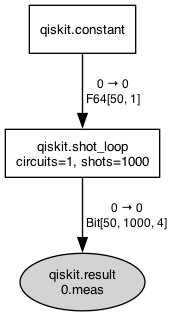

In [21]:
quantum_program.draw()

We can go further and compute expectation values from the raw shot data before packaging everything into a single program.

In [22]:
raw_data = shot_loop([circuit], shots=1000, parameter_values=[sweep])

zs = np.array([
    [1,0,0,0], 
    [0,1,1,1], 
    [1,1,1,1]], dtype=bool)[:,None,None,:]
per_shot_parities = (raw_data[0]["meas"] & zs).parity(axis=3)
proto_evs = per_shot_parities.mean(axis=2)
evs = 1 - 2 * proto_evs

quantum_program = build({
    "my_evs": evs, 
    "sweep": sweep, 
    "all_shots": raw_data
})

Here's the resulting graph — it now includes the classical post-processing alongside the quantum execution.

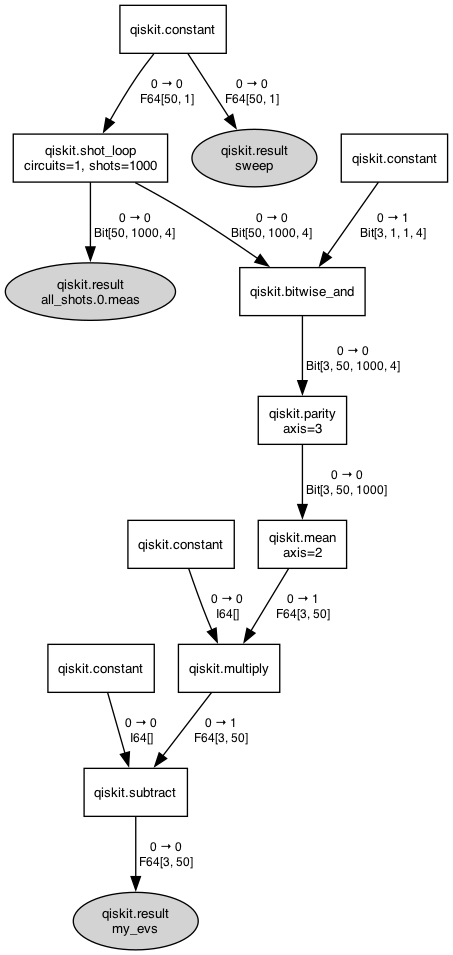

In [23]:
quantum_program.draw()

Now we run this composite program on the simulator and collect the results.

In [24]:
quantum_program = build({"my_evs": evs, "sweep": sweep, "all_shots": raw_data})

job = BasicProgramSimulator().run(quantum_program)
data = job.result()

Finally, let's plot the computed expectation values against the parameter sweep.

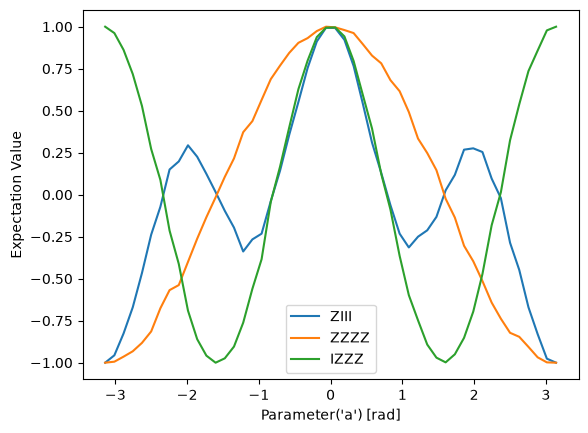

In [25]:
import matplotlib.pyplot as plt

plt.plot(data["sweep"], data["my_evs"].T, label=["ZIII", "ZZZZ", "IZZZ"])
plt.xlabel("Parameter('a') [rad]")
plt.ylabel("Expectation Value")
plt.legend()

### Exercises

1. **Add an observable** — The notebook computes `⟨ZIII⟩`, `⟨IZZZ⟩`, and `⟨ZZZZ⟩`. Add `⟨XXXX⟩` to the `zs` array (hint: it's not a Z-basis parity — you'll need to think about what basis change is required, or whether the current approach can handle X observables at all).

2. **Inspect the listing** — After building the composite program with `evs`, `sweep`, and `all_shots`, read the `quantum_program.listing()` output. Draw the dataflow graph by hand on paper, labeling each node with its operation and shape. Verify it matches the `.draw()` output.

3. **Two circuits** — Define a second circuit (e.g. a simple product state) and pass both circuits to `shot_loop`. Inspect how the program IR changes when multiple circuits are involved.